Select a suitable series dataset from kaggle preprocess the data and design,build and train a reccurent neural network (RNN) model using the selected dataset,Evaluate the models performance using appropriate evaluation metrics and display its prediction accuracy.

In [1]:
import pandas as pd

df = pd.read_csv('/content/daily-minimum-temperatures-in-me.csv')

df.head()

,Date,Daily minimum temperatures
0,1/1/1981,20.7
1,1/2/1981,17.9
2,1/3/1981,18.8
3,1/4/1981,14.6
4,1/5/1981,15.8


In [10]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.head())
print(df.tail())
print(df.columns)

(3650, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Date                        3650 non-null   object
 1   Daily minimum temperatures  3650 non-null   object
dtypes: object(2)
memory usage: 57.2+ KB
None
            Date Daily minimum temperatures
count       3650                       3650
unique      3650                        230
top     1/1/1981                         10
freq           1                         51
Date                          0
Daily minimum temperatures    0
dtype: int64
       Date Daily minimum temperatures
0  1/1/1981                       20.7
1  1/2/1981                       17.9
2  1/3/1981                       18.8
3  1/4/1981                       14.6
4  1/5/1981                       15.8
            Date Daily minimum temperatures
3645  12/27/1990                       

In [27]:
print(df.isnull().sum())

Date    0
Temp    3
dtype: int64


In [33]:
df['Temp'] = pd.to_numeric(df['Temp'], errors='coerce')

df = df.dropna()

df = df.reset_index(drop=True)

print(df.isnull().sum())

Date    0
Temp    0
dtype: int64


Column-এর নাম সহজ করো

In [12]:
df.columns = ['Date', 'Temp']

df.head()

,Date,Temp
0,1/1/1981,20.7
1,1/2/1981,17.9
2,1/3/1981,18.8
3,1/4/1981,14.6
4,1/5/1981,15.8


In [34]:
data = df['Temp'].values
data = data.reshape(-1, 1)

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
data = scaler.fit_transform(data)

print("Data shape:", data.shape)
print("NaN values:", np.isnan(data).sum())

Data shape: (3647, 1)
NaN values: 0


In [36]:
train_size = int(len(data) * 0.80)

train_data = data[:train_size]
test_data = data[train_size:]

print("Train data:", train_data.shape)
print("Test data:", test_data.shape)

Train data: (2917, 1)
Test data: (730, 1)


Predict previous 12 months temperature then predict next 12 months temperature

In [37]:
import numpy as np

def create_dataset(dataset, time_step=12):
    X, y = [], []

    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i + time_step, 0])
        y.append(dataset[i + time_step, 0])

    return np.array(X), np.array(y)


X_train, y_train = create_dataset(train_data, 12)
X_test, y_test = create_dataset(test_data, 12)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2905, 12)
y_train: (2905,)
X_test: (718, 12)
y_test: (718,)


Reshape for RNN

In [39]:
X_train = X_train.reshape(X_train.shape[0], 12, 1)
X_test = X_test.reshape(X_test.shape[0], 12, 1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (2905, 12, 1)
X_test: (718, 12, 1)


Create simple RNN model

In [40]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

model = Sequential()

model.add(SimpleRNN(
    50,
    activation='tanh',
    input_shape=(12, 1)
))

model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Model train

In [41]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0311 - mae: 0.1242 - val_loss: 0.0098 - val_mae: 0.0783
Epoch 2/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0104 - mae: 0.0802 - val_loss: 0.0088 - val_mae: 0.0741
Epoch 3/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0096 - mae: 0.0773 - val_loss: 0.0075 - val_mae: 0.0681
Epoch 4/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0093 - mae: 0.0760 - val_loss: 0.0073 - val_mae: 0.0675
Epoch 5/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - mae: 0.0753 - val_loss: 0.0072 - val_mae: 0.0669
Epoch 6/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0090 - mae: 0.0743 - val_loss: 0.0076 - val_mae: 0.0690
Epoch 7/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - mae: 0.0745 - val_loss: 0.0071 - val_mae: 0.0668
Epoch 8/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0089 - mae: 0.0741 - val_loss: 0.0075 - val_mae: 0.0686
Epoch 9/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0091 - mae

Temperature prediction

In [42]:
predictions = model.predict(X_test)

print("Predictions shape:", predictions.shape)
print("Actual shape:", y_test.shape)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Predictions shape: (718, 1)
Actual shape: (718,)


Compare actual and predicted temperature


In [43]:
predictions = scaler.inverse_transform(predictions)

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

import pandas as pd

result = pd.DataFrame({
    'Actual Temperature': actual.flatten(),
    'Predicted Temperature': predictions.flatten()
})

print(result.head(10))

   Actual Temperature  Predicted Temperature
0                12.1              13.733843
1                13.4              12.598298
2                17.3              13.509495
3                19.4              15.500893
4                16.6              16.303272
5                13.9              14.663513
6                13.1              13.696700
7                16.0              13.669150
8                14.5              15.421904
9                15.0              14.074879


Evaluate model

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(actual, predictions)

mse = mean_squared_error(actual, predictions)

rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 1.7542431306042046
MSE: 4.945505927207572
RMSE: 2.2238493490359397


Actual vs Predicted Graph

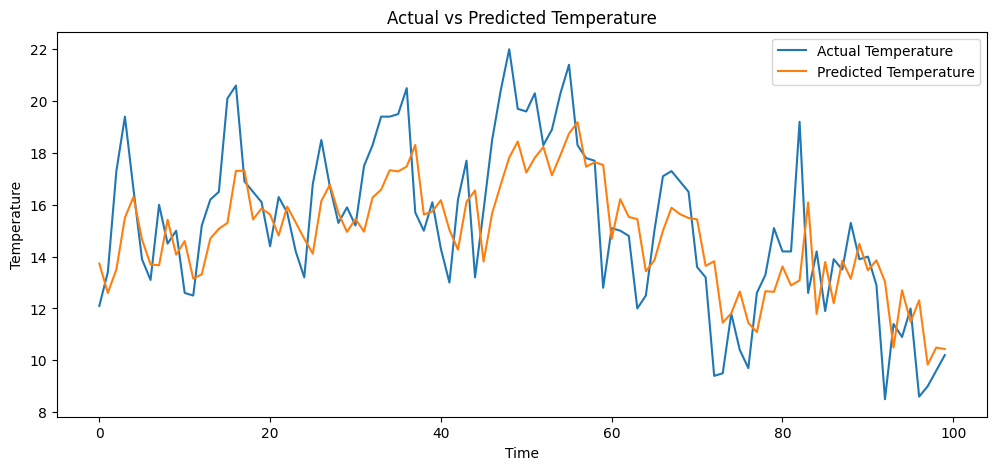

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(actual[:100], label='Actual Temperature')

plt.plot(predictions[:100], label='Predicted Temperature')

plt.title('Actual vs Predicted Temperature')

plt.xlabel('Time')

plt.ylabel('Temperature')

plt.legend()

plt.show()